## import the segment wise absolute correlation matrices

In [6]:
from pathlib import Path
import pandas as pd

abs_segment_base = Path('correlation_matrices_segment_wise_absolute')
matrix_files = list(abs_segment_base.rglob('*.csv'))

if matrix_files:
    sample = pd.read_csv(matrix_files[0], index_col=0)
    print(f"Found {len(matrix_files)} absolute matrices. Sample shape: {sample.shape}")


Found 2632 absolute matrices. Sample shape: (19, 19)


## filter the subjects for our study

In [7]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from itertools import combinations

# Filter subjects
subject_ids = [64, 65, 69, 70, 75, 77, 78, 79, 80, 81, 82, 83, 84, 86, 87, 89, 90, 94, 96, 103]
formatted_subjects = [f"sub-NORB{sid:05d}" for sid in subject_ids]

# Extract first 12 segments for session 1
n_segments = 12
subject_matrices = {}

for subj in formatted_subjects:
    subj_dir = abs_segment_base / subj / "ses-1"
    if not subj_dir.exists():
        print(f"Warning: directory not found for {subj}")
        continue
        
    csv_files = sorted(subj_dir.glob('*.csv'))
    if len(csv_files) < n_segments:
        print(f"Warning: {subj} has less than {n_segments} segments")
        
    matrices = []
    for csv_file in csv_files[:n_segments]:
        df = pd.read_csv(csv_file, index_col=0)
        matrices.append(df.values)
        
    if matrices:
        avg_matrix = np.mean(matrices, axis=0)
        subject_matrices[subj] = pd.DataFrame(avg_matrix, index=df.index, columns=df.columns)
        
print(f"Processed {len(subject_matrices)} subjects")


Processed 20 subjects


## calculate edge eigenvector centrality for all edges of the filtered subjects

according to brohl & lehnertz, edge eigenvector centrality for a weighted network is calculated by:
1. constructing a line graph where nodes represent the edges of the original graph.
2. assigning the weight between two adjacent edges in the line graph as the **average** of their individual correlation weights.
3. computing the standard eigenvector centrality on this weighted line graph.


In [8]:
import networkx as nx
import numpy as np

def compute_edge_eigenvector_centrality(G, weight='weight'):
    L = nx.line_graph(G)
    for e in L.edges():
        edge1, edge2 = e
        w1 = G[edge1[0]][edge1[1]].get(weight, 0)
        w2 = G[edge2[0]][edge2[1]].get(weight, 0)
        L[edge1][edge2]['weight'] = (w1 + w2) / 2.0
    try:
        ec = nx.eigenvector_centrality(L, weight='weight', max_iter=1000)
    except:
        ec = nx.eigenvector_centrality_numpy(L, weight='weight')
    
    normalized_ec = {}
    for edge_tuple, val in ec.items():
        normalized_ec[tuple(sorted(list(edge_tuple)))] = val
    return normalized_ec

subject_edge_centrality = {}

for subj, df in subject_matrices.items():
    G = nx.from_pandas_adjacency(df)
    
    ec = compute_edge_eigenvector_centrality(G, weight='weight')
    
    subject_edge_centrality[subj] = ec

print(f"Calculated edge eigenvector centrality for {len(subject_edge_centrality)} subjects")


Calculated edge eigenvector centrality for 20 subjects


## plot edge eigenvector centrality heatmap

Text(595.7222222222223, 0.5, 'Subjects (Youngest to Oldest)')

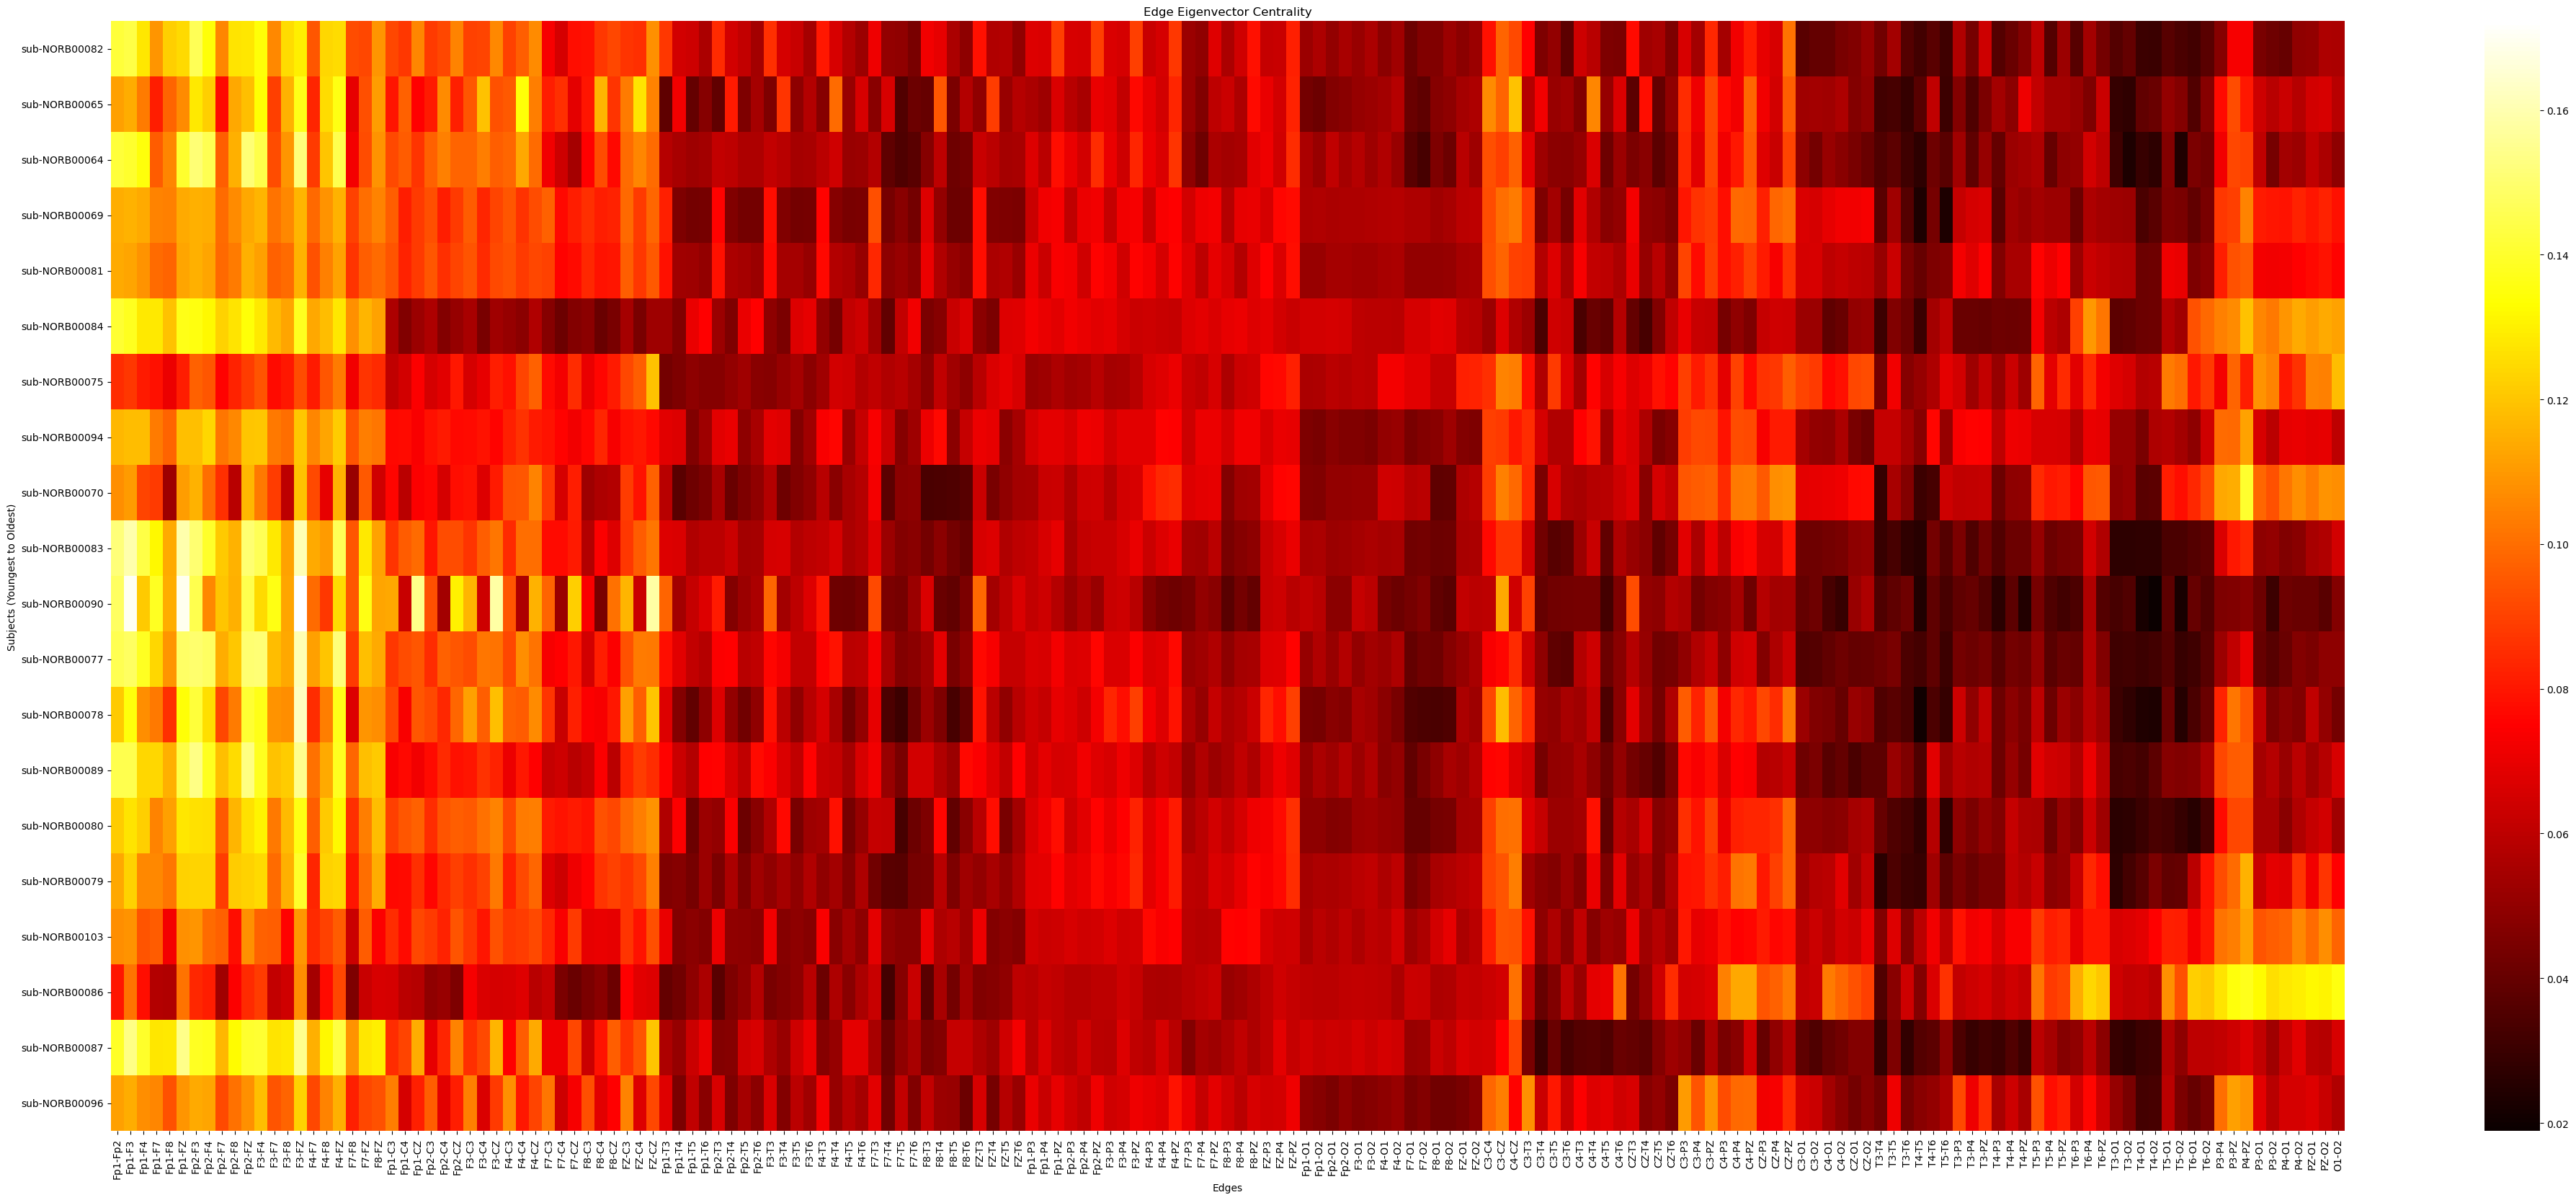

In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Hardcoded edge order
edge_labels = [
    'Fp1-Fp2', 'Fp1-F3', 'Fp1-F4', 'Fp1-F7', 'Fp1-F8', 'Fp1-FZ', 'Fp2-F3',
    'Fp2-F4', 'Fp2-F7', 'Fp2-F8', 'Fp2-FZ', 'F3-F4', 'F3-F7', 'F3-F8', 'F3-FZ',
    'F4-F7', 'F4-F8', 'F4-FZ', 'F7-F8', 'F7-FZ', 'F8-FZ', 'Fp1-C3', 'Fp1-C4',
    'Fp1-CZ', 'Fp2-C3', 'Fp2-C4', 'Fp2-CZ', 'F3-C3', 'F3-C4', 'F3-CZ', 'F4-C3',
    'F4-C4', 'F4-CZ', 'F7-C3', 'F7-C4', 'F7-CZ', 'F8-C3', 'F8-C4', 'F8-CZ',
    'FZ-C3', 'FZ-C4', 'FZ-CZ', 'Fp1-T3', 'Fp1-T4', 'Fp1-T5', 'Fp1-T6',
    'Fp2-T3', 'Fp2-T4', 'Fp2-T5', 'Fp2-T6', 'F3-T3', 'F3-T4', 'F3-T5', 'F3-T6',
    'F4-T3', 'F4-T4', 'F4-T5', 'F4-T6', 'F7-T3', 'F7-T4', 'F7-T5', 'F7-T6',
    'F8-T3', 'F8-T4', 'F8-T5', 'F8-T6', 'FZ-T3', 'FZ-T4', 'FZ-T5', 'FZ-T6',
    'Fp1-P3', 'Fp1-P4', 'Fp1-PZ', 'Fp2-P3', 'Fp2-P4', 'Fp2-PZ', 'F3-P3',
    'F3-P4', 'F3-PZ', 'F4-P3', 'F4-P4', 'F4-PZ', 'F7-P3', 'F7-P4', 'F7-PZ',
    'F8-P3', 'F8-P4', 'F8-PZ', 'FZ-P3', 'FZ-P4', 'FZ-PZ', 'Fp1-O1', 'Fp1-O2',
    'Fp2-O1', 'Fp2-O2', 'F3-O1', 'F3-O2', 'F4-O1', 'F4-O2', 'F7-O1', 'F7-O2',
    'F8-O1', 'F8-O2', 'FZ-O1', 'FZ-O2', 'C3-C4', 'C3-CZ', 'C4-CZ', 'C3-T3',
    'C3-T4', 'C3-T5', 'C3-T6', 'C4-T3', 'C4-T4', 'C4-T5', 'C4-T6', 'CZ-T3',
    'CZ-T4', 'CZ-T5', 'CZ-T6', 'C3-P3', 'C3-P4', 'C3-PZ', 'C4-P3', 'C4-P4',
    'C4-PZ', 'CZ-P3', 'CZ-P4', 'CZ-PZ', 'C3-O1', 'C3-O2', 'C4-O1', 'C4-O2',
    'CZ-O1', 'CZ-O2', 'T3-T4', 'T3-T5', 'T3-T6', 'T4-T5', 'T4-T6', 'T5-T6',
    'T3-P3', 'T3-P4', 'T3-PZ', 'T4-P3', 'T4-P4', 'T4-PZ', 'T5-P3', 'T5-P4',
    'T5-PZ', 'T6-P3', 'T6-P4', 'T6-PZ', 'T3-O1', 'T3-O2', 'T4-O1', 'T4-O2',
    'T5-O1', 'T5-O2', 'T6-O1', 'T6-O2', 'P3-P4', 'P3-PZ', 'P4-PZ', 'P3-O1',
    'P3-O2', 'P4-O1', 'P4-O2', 'PZ-O1', 'PZ-O2', 'O1-O2',
]

# Load ages and sort subjects increasing (oldest top, youngest bottom)
ages_df = pd.read_csv('age_acq_time_sorted.csv')
target_labels = [f"{subj}_ses-1" for subj in formatted_subjects]
ages_filtered = ages_df[ages_df['label'].isin(target_labels)].copy()
# User requested increasing order of their age
ages_filtered = ages_filtered.sort_values('age_acq_time', ascending=False)

sorted_subject_labels = ages_filtered['label'].tolist()
sorted_subjects = [label.split('_')[0] for label in sorted_subject_labels]

# Prepare data for heatmap
heatmap_data = []
valid_subjects = []

for subj in sorted_subjects:
    if subj in subject_edge_centrality:
        valid_subjects.append(subj)
        ec = subject_edge_centrality[subj]
        row_data = []
        for e in edge_labels:
            u, v = e.split('-')
            val = ec.get((u, v), ec.get((v, u), 0))
            row_data.append(val)
        heatmap_data.append(row_data)

heatmap_data = np.array(heatmap_data)

# Plot heatmap
plt.figure(figsize=(50, 20))
sns.heatmap(heatmap_data, cmap='hot', xticklabels=edge_labels, yticklabels=valid_subjects)
plt.title('Edge Eigenvector Centrality')
plt.xlabel('Edges')
plt.ylabel('Subjects (Youngest to Oldest)')


## calculate weighted jaccard index for edge eigenvector centrality

this cell calculates the weighted jaccard index (min/max) per segment for all 171 edges between every pair of subjects.
for each edge, the jaccard index is computed for each of the 12 segments by dividing the minimum centrality value by the maximum value. these 12 values are then averaged to give exactly 171 jaccard indices per subject pair (one for each edge). finally, the average of these 171 indices is also computed.


In [10]:
import networkx as nx
import numpy as np
import pandas as pd
from itertools import combinations
from pathlib import Path

def compute_edge_eigenvector_centrality(G, weight='weight'):
    L = nx.line_graph(G)
    for e in L.edges():
        edge1, edge2 = e
        w1 = G[edge1[0]][edge1[1]].get(weight, 0)
        w2 = G[edge2[0]][edge2[1]].get(weight, 0)
        L[edge1][edge2]['weight'] = (w1 + w2) / 2.0
    try:
        ec = nx.eigenvector_centrality(L, weight='weight', max_iter=1000)
    except:
        ec = nx.eigenvector_centrality_numpy(L, weight='weight')
    
    normalized_ec = {}
    for edge_tuple, val in ec.items():
        normalized_ec[tuple(sorted(list(edge_tuple)))] = val
    return normalized_ec

subject_segment_ec = {}

for subj in formatted_subjects:
    subj_dir = abs_segment_base / subj / "ses-1"
    if not subj_dir.exists():
        continue

    csv_files = sorted(subj_dir.glob('*.csv'))
    subject_segment_ec[subj] = []

    for csv_file in csv_files[:n_segments]:
        df = pd.read_csv(csv_file, index_col=0)
        G = nx.from_pandas_adjacency(df)

        ec = compute_edge_eigenvector_centrality(G, weight='weight')
        subject_segment_ec[subj].append(ec)

print(f"Calculated individual segment edge eigenvector centrality for {len(subject_segment_ec)} subjects.")

sample_subj = formatted_subjects[0]
edges_list = list(subject_segment_ec[sample_subj][0].keys())

pair_jaccard_avg = {}
pair_jaccard_all_edges = {}

for subj_A, subj_B in combinations(formatted_subjects, 2):
    edge_jaccards = []
    for e in edges_list:
        segment_jaccards = []
        for s in range(n_segments):
            if s < len(subject_segment_ec[subj_A]) and s < len(subject_segment_ec[subj_B]):
                val_A = subject_segment_ec[subj_A][s].get(e, 0)
                val_B = subject_segment_ec[subj_B][s].get(e, 0)
                if max(val_A, val_B) > 0:
                    jaccard_s = min(val_A, val_B) / max(val_A, val_B)
                else:
                    jaccard_s = 0
                segment_jaccards.append(jaccard_s)
        edge_jaccard_avg = np.mean(segment_jaccards) if segment_jaccards else 0
        edge_jaccards.append(edge_jaccard_avg)
    pair_jaccard_all_edges[(subj_A, subj_B)] = edge_jaccards
    pair_jaccard_avg[(subj_A, subj_B)] = np.mean(edge_jaccards)

print(f"Calculated average Jaccard index for {len(pair_jaccard_avg)} subject pairs.")


Calculated individual segment edge eigenvector centrality for 20 subjects.
Calculated average Jaccard index for 190 subject pairs.


## plot jaccard index heatmap for subject pairs

plots the jaccard index for all 171 edges across all 190 subject pairs. the y-axis displays subject pairs sorted by the difference in their ages, with the smallest age difference at the bottom.

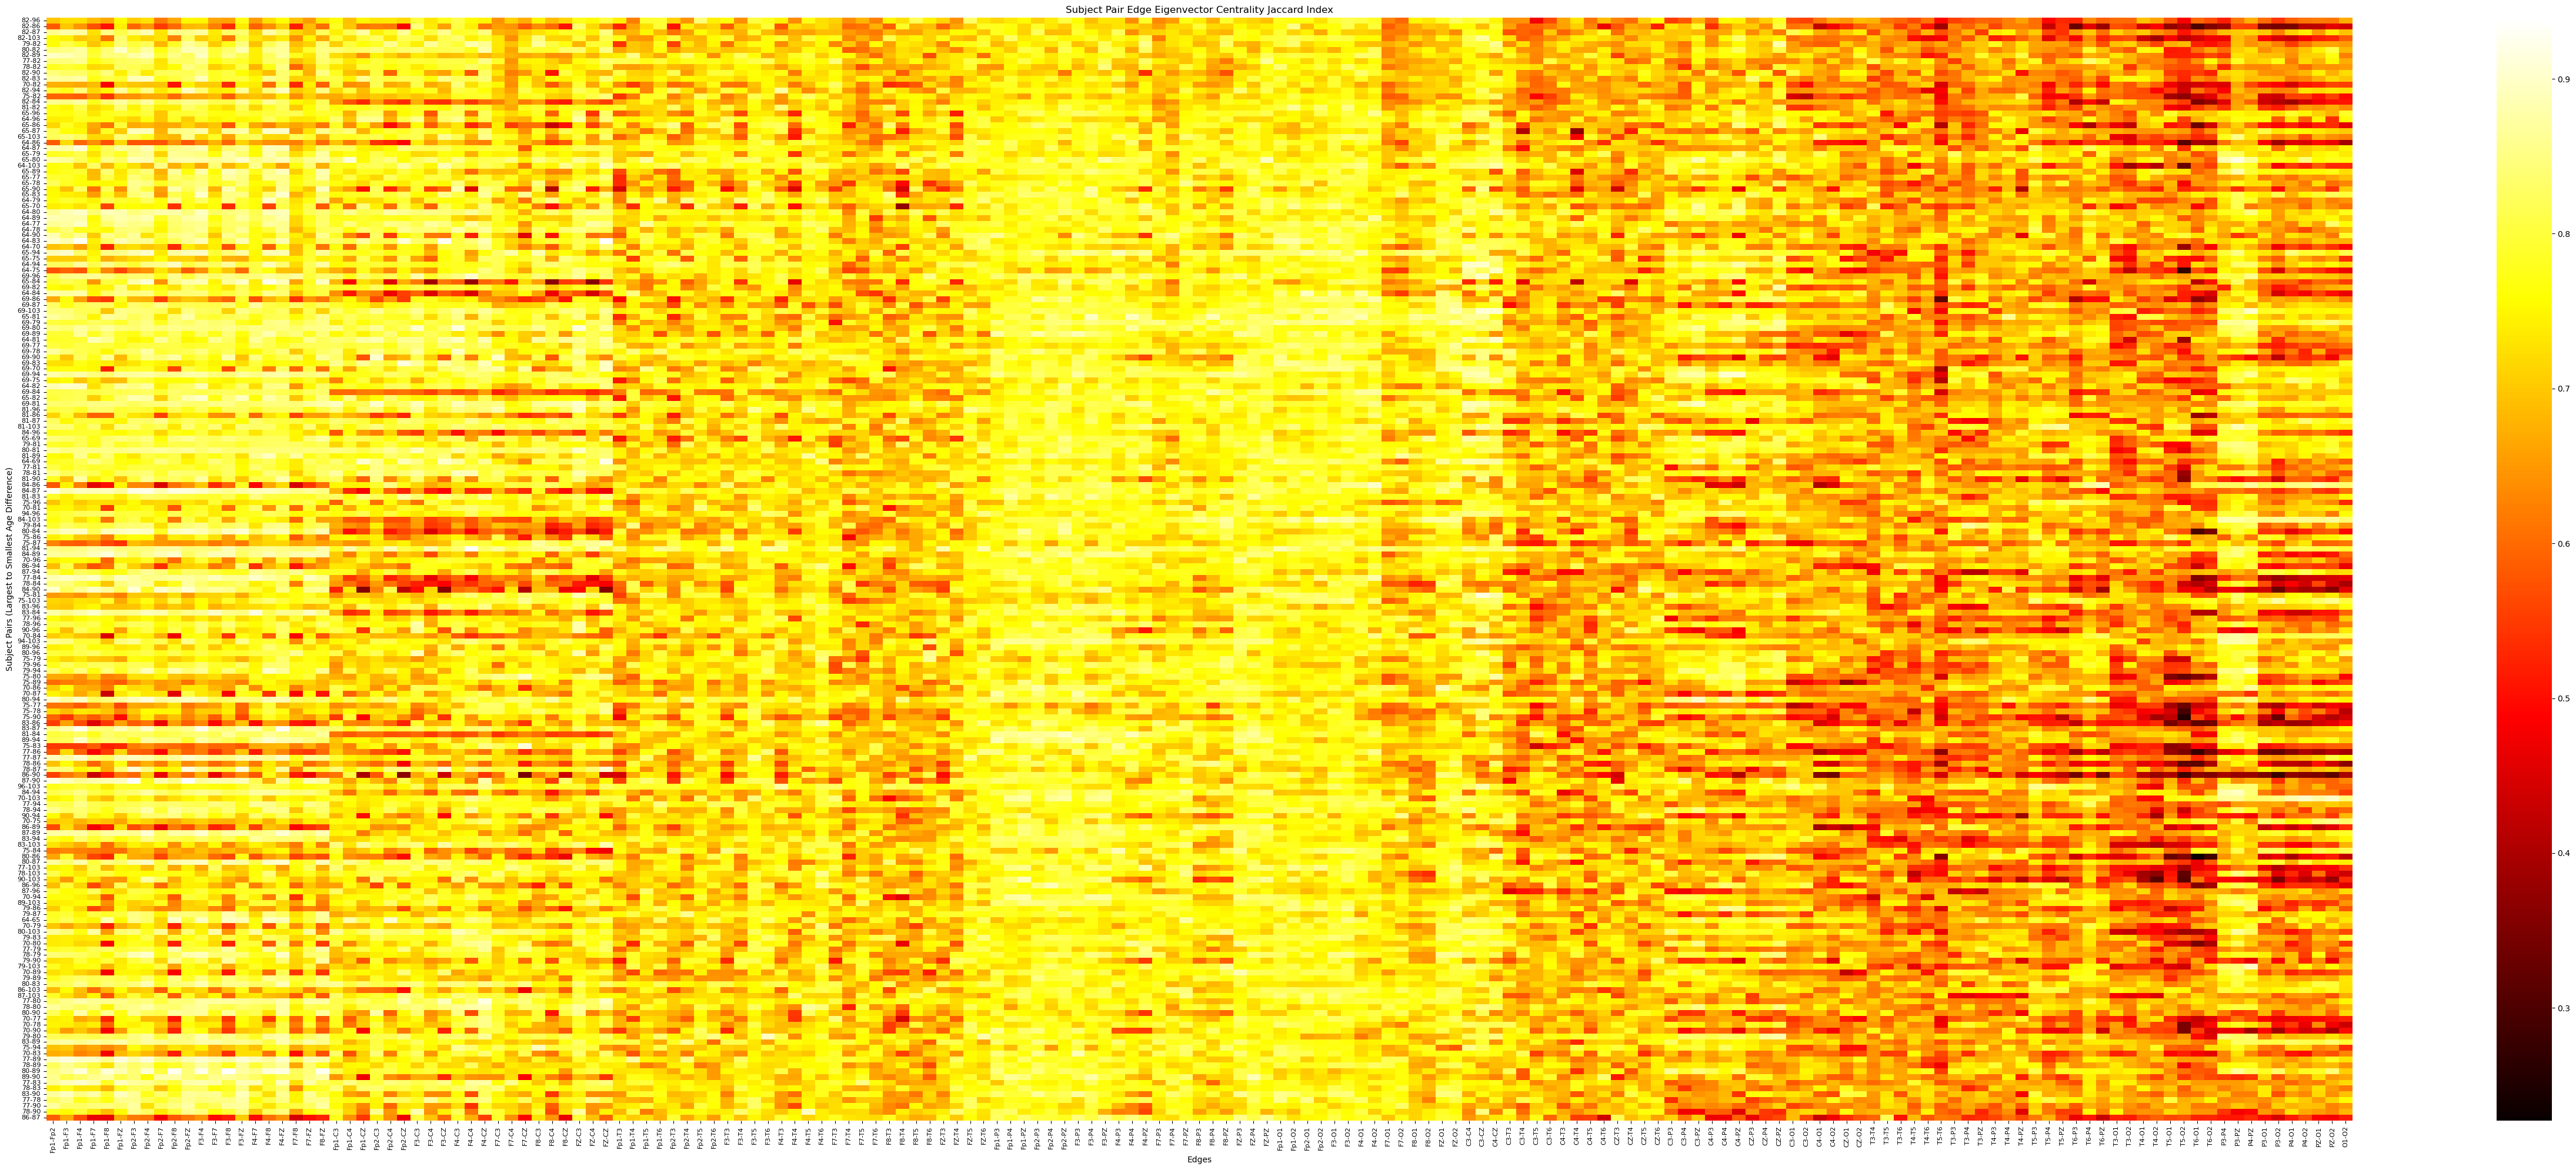

In [11]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Get the age data
ages_df = pd.read_csv('age_acq_time_sorted.csv')
target_labels = [f"{subj}_ses-1" for subj in formatted_subjects]
ages_filtered = ages_df[ages_df['label'].isin(target_labels)]

age_dict = {}
for idx, row in ages_filtered.iterrows():
    subj = row['label'].split('_')[0]
    age_dict[subj] = row['age_acq_time']

# Calculate age difference for each pair
pair_age_diff = {}
for pair in pair_jaccard_all_edges.keys():
    subj_A, subj_B = pair
    diff = abs(age_dict[subj_A] - age_dict[subj_B])
    pair_age_diff[pair] = diff

# Sort pairs by age difference descending (largest diff at top, smallest diff at bottom)
sorted_pairs = sorted(pair_age_diff.keys(), key=lambda x: pair_age_diff[x], reverse=True)

# Map original edges_list to edge_labels order
edge_to_index = {e: i for i, e in enumerate(edges_list)}

heatmap_data = []
yticklabels = []

for pair in sorted_pairs:
    p0 = str(int(pair[0].replace('sub-NORB', '')))
    p1 = str(int(pair[1].replace('sub-NORB', '')))
    yticklabels.append(f"{p0}-{p1}")
    row_data = []
    for e in edge_labels:
        u, v = e.split('-')
        edge_tuple = tuple(sorted([u, v]))
        idx = edge_to_index[edge_tuple]
        val = pair_jaccard_all_edges[pair][idx]
        row_data.append(val)
    heatmap_data.append(row_data)

heatmap_data = np.array(heatmap_data)

# Plot heatmap
plt.figure(figsize=(50, 20))
sns.heatmap(heatmap_data, cmap='hot', xticklabels=edge_labels, yticklabels=yticklabels)
plt.title('Subject Pair Edge Eigenvector Centrality Jaccard Index')
plt.xlabel('Edges')
plt.ylabel('Subject Pairs (Largest to Smallest Age Difference)')
plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
